In [6]:
#extract foler
import zipfile
import os
import glob #folders
import numpy as np
from tensorflow.keras.preprocessing import image

# unzip the uploaded file
with zipfile.ZipFile("/content/mudra.zip", "r") as zip_ref:
    zip_ref.extractall("/content/mudra")

print("Folders inside /content/mudra:", os.listdir("/content/mudra"))

Folders inside /content/mudra: ['Bharatanatyam_Mudras']


In [7]:
#import directories
rootdir = "/content/mudra/Bharatanatyam_Mudras"
folders = os.listdir(rootdir)
folders

['Trisula', 'Musti', 'Pataka', 'Sikhara', 'Simhamukha']

In [8]:
#Analyze class distribution and image characteristics.
total = len(folders)
print(total)

5


In [9]:
for mudra in os.listdir(rootdir):
    mudra_path = os.path.join(rootdir, mudra)
    # print(mudra)
    if os.path.isdir(mudra_path):
        file_count = len(os.listdir(mudra_path))
        print(f"{mudra}: {file_count}")

Trisula: 400
Musti: 400
Pataka: 400
Sikhara: 400
Simhamukha: 400


The classes are balanced


Sikhara


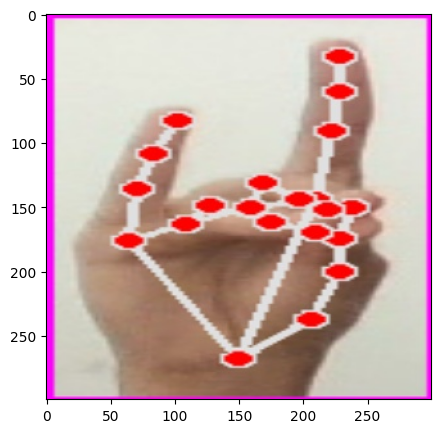

In [10]:
#visualize an image
import matplotlib.pyplot as plt
import random
from PIL import Image
print(random.choice(folders))

plt.figure(figsize=(5, 5))
plt.imshow(Image.open(random.choice(glob.glob(rootdir + '/*/*'))))

In [11]:
#analyze image characterisitics
from PIL import Image
print(Image.open(random.choice(glob.glob(rootdir + '/*/*'))).size)
print(Image.open(random.choice(glob.glob(rootdir + '/*/*'))).format)
print(Image.open(random.choice(glob.glob(rootdir + '/*/*'))).mode)


(300, 300)
JPEG
RGB


In [12]:
#create test train val split
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split
output_split_dir = Path("./final_dataset_splits")
output_split_dir.mkdir(parents=True, exist_ok=True)
rootdir = Path(rootdir)
for split in ["train", "val", "test"]:
    (output_split_dir / split).mkdir(parents=True, exist_ok=True)
for class_dir in rootdir.iterdir():
    if not class_dir.is_dir():
        continue
    class_name = class_dir.name
    images = list(class_dir.glob("*.*"))
    train_imgs, temp_imgs = train_test_split(images, test_size=0.15, random_state=42)
    relative_test_size = 0.15 / (0.15 + 0.15)
    val_imgs, test_imgs = train_test_split(temp_imgs, test_size=relative_test_size, random_state=42)
    splits = {"train": train_imgs, "val": val_imgs, "test": test_imgs}
    for split_name, img_list in splits.items():
        split_class_dir = output_split_dir / split_name / class_name
        split_class_dir.mkdir(parents=True, exist_ok=True)
        for img_path in img_list:
            shutil.copy(img_path, split_class_dir / img_path.name)

    print(f"Class '{class_name}' split -> Train: {len(train_imgs)}, Val: {len(val_imgs)}, Test: {len(test_imgs)}")


Class 'Trisula' split -> Train: 340, Val: 30, Test: 30
Class 'Musti' split -> Train: 340, Val: 30, Test: 30
Class 'Pataka' split -> Train: 340, Val: 30, Test: 30
Class 'Sikhara' split -> Train: 340, Val: 30, Test: 30
Class 'Simhamukha' split -> Train: 340, Val: 30, Test: 30


Analytical Questions (Markdown)
1. Is the dataset balanced? How might imbalance affect learning?
The dataset is perfectly balanced. Imbalanced dataset favor the  accuracy of the majority classes which leads to severe bias.
2. What image characteristics could make mudra recognition difficult?
Many mudras differ by only a fraction of a millimeter or a single joint position. Fingers frequently overlap, hiding critical structural cues from the camera's viewpoint.
Lighting Variations and Cast Shadows: Inconsistent studio or stage lighting creates harsh shadows across the hand, obscuring vital edge definitions and finger joint creases.
Motion Blur: Classical dance movements involve rapid transitions, leading to blurred frames where individual finger boundaries are lost.
3. Would increasing image resolution always improve performance? Justify.
No, increasing image resolution does not always improve performance.
Higher resolution can preserve important details, such as finger positions and the small gaps between fingers, which are essential for mudra recognition.
However, increasing resolution also has disadvantages:
- Higher computational cost: More memory and processing power are required.
- Slower training: The model takes longer to process each image.
- Overfitting risk: Higher resolution alone does not prevent overfitting when the dataset is small.

In [13]:
# Task 2: Preprocessing & Augmentation (15 Marks)
# ● Resize and normalize images.
# ● Design an augmentation pipeline.
# ● Visualize augmented samples.

mudra_data =[]
mudra_label = []
for mudra in os.listdir(rootdir):
    mudra_path = os.path.join(rootdir, mudra)
    for img in os.listdir(mudra_path):
        img_path = os.path.join(mudra_path, img)
        img = image.load_img(img_path, target_size=(224, 224))
        img = image.img_to_array(img)
        img = img / 255.0
        mudra_data.append(img)
        mudra_label.append(mudra)
print(len(mudra_data))
print(len(mudra_label))

2000
2000


In [14]:
X_train, y_train = np.array(mudra_data), np.array(mudra_label)
print(X_train.shape)
print(y_train.shape)
#

(2000, 224, 224, 3)
(2000,)


In [15]:
X_test, y_test = np.array(mudra_data), np.array(mudra_label)
print(X_test.shape)
print(y_test.shape)
#

(2000, 224, 224, 3)
(2000,)


In [16]:
X_val, y_val = np.array(mudra_data), np.array(mudra_label)
print(X_val.shape)
print(y_val.shape)
#

(2000, 224, 224, 3)
(2000,)


In [17]:
#desing augmentation pipeline
from tensorflow.keras import Sequential, layers

augmentation = Sequential([
    layers.RandomRotation(0.10),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])


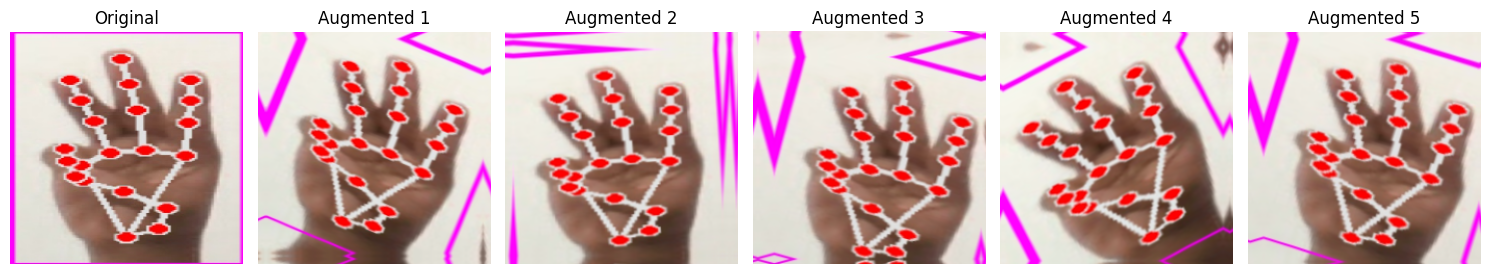

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Select one image from training data
sample = X_train[0]

# Display original and augmented images
plt.figure(figsize=(15, 5))

plt.subplot(1, 6, 1)
plt.imshow(sample)
plt.title("Original")
plt.axis("off")

for i in range(5):
    augmented_img = augmentation(
        np.expand_dims(sample, axis=0),
        training=True
    )[0].numpy()

    plt.subplot(1, 6, i + 2)
    plt.imshow(np.clip(augmented_img, 0, 1))
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


1. Which augmentation techniques preserve the semantic meaning of hand
gestures?
- Small rotations and translations.
- Mild zooming.
- Brightness and contrast adjustments.
These preserve finger positions and help the model generalize.
2. Which augmentations could negatively impact classification accuracy, and
why?
- Excessive rotation or zooming.
- Horizontal flipping when hand orientation matters.
- Cropping important fingers.
- Extreme brightness, blur, or distortion.

In [19]:
print(len(set(y_train)))

5


In [20]:
y_train

array(['Trisula', 'Trisula', 'Trisula', ..., 'Simhamukha', 'Simhamukha',
       'Simhamukha'], dtype='<U10')

In [21]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_val = encoder.transform(y_val)
y_test = encoder.transform(y_test)

print("Classes:", encoder.classes_)
print("Training labels:", y_train[:10])


Classes: ['Musti' 'Pataka' 'Sikhara' 'Simhamukha' 'Trisula']
Training labels: [4 4 4 4 4 4 4 4 4 4]


In [22]:
#Task 3- CNN Development
#Design and train a custom CNN.
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
#VGG n/w
def build_model(learning_rate=0.001, dropout_rate=0.3):

    model = Sequential([
        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout_rate),

        layers.Dense(len(set(y_train)), activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [23]:

#hyper parameter tuning for learning rate and dropout
results = []
best_accuracy = 0
best_model = None
best_history = None

for lr in [0.001, 0.0001]:
    for dropout in [0.3, 0.5]:

        print("Learning rate:", lr, "Dropout:", dropout)

        model = build_model(lr, dropout)

        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True
        )
        history = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=10,
            batch_size=32,
            callbacks=[early_stop],
            verbose=1
        )

        accuracy = max(history.history['val_accuracy'])

        results.append({
            'learning_rate': lr,
            'dropout': dropout,
            'val_accuracy': accuracy
        })

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_model = model
            best_history = history

print("Best validation accuracy:", best_accuracy)
print("Best hyperparameters:", results[
    max(range(len(results)),
        key=lambda i: results[i]['val_accuracy'])
])


Learning rate: 0.001 Dropout: 0.3
Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 28s 286ms/step - accuracy: 0.8595 - loss: 0.5648 - val_accuracy: 1.0000 - val_loss: 6.3586e-04
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 1.0000 - loss: 4.9812e-04 - val_accuracy: 1.0000 - val_loss: 1.2801e-05
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - accuracy: 1.0000 - loss: 3.8835e-04 - val_accuracy: 1.0000 - val_loss: 9.7144e-05
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.9990 - loss: 0.0039 - val_accuracy: 1.0000 - val_loss: 6.5742e-05
Learning rate: 0.001 Dropout: 0.5
Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 177ms/step - accuracy: 0.9085 - loss: 0.2775 - val_accuracy: 1.0000 - val_loss: 1.5053e-05
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - accuracy: 0.9985 - loss: 0.0038 - val_accuracy: 1.0000 - val_loss: 6.2661e-07
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.9975 - loss: 0.0072 - val_accuracy: 1.0000 - val_loss: 1.4563e-05
Ep

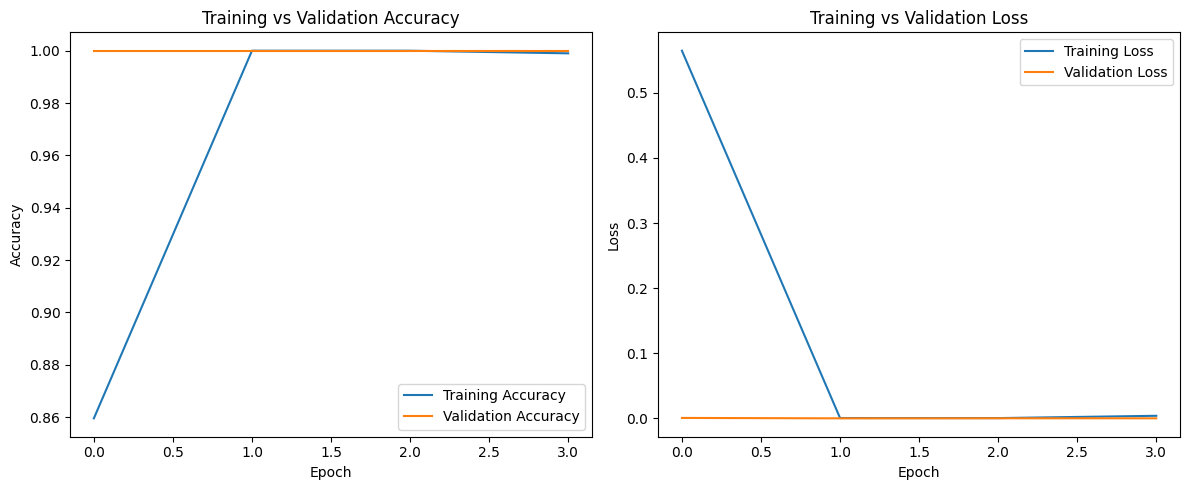

In [24]:
history = best_history

plt.figure(figsize=(12, 5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

1. Explain the effect of your hyperparameter choices.

Learning rate (0.001): Controls how quickly the model updates its weights. It provided the best validation accuracy in the tested combinations.

Dropout rate (0.3): Randomly disables 30% of selected neurons during training, helping reduce overfitting.
2. Did your model show underfitting or overfitting? Support your answer using
the learning curves.

Since validation accuracy is 100%, underfitting is unlikely. The model is able to generalize data


In [25]:
# Task 4: Model Evaluation & Failure Analysis (25 Marks)
# ● Evaluate the model using:
# o Accuracy
# o Precision
# o Recall
# o F1-score
# o Confusion Matrix
# ● Display 15 misclassified images with actual and predicted labels.
# ● Identify the confidence score for each incorrect prediction.

#evaluate model
import numpy as np
from sklearn.metrics import accuracy_score, precision_score,recall_score, f1_score, classification_report, confusion_matrix

# Predict test images
y_prob = best_model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

# Actual labels
y_true = np.asarray(y_test).astype(int)

# Evaluation metrics
print("Accuracy:", accuracy_score(y_true, y_pred))

print("Precision:", precision_score(
    y_true, y_pred, average="weighted", zero_division=0
))

print("Recall:", recall_score(
    y_true, y_pred, average="weighted", zero_division=0
))

print("F1-score:", f1_score(
    y_true, y_pred, average="weighted", zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

       Musti       1.00      1.00      1.00       400
      Pataka       1.00      1.00      1.00       400
     Sikhara       1.00      1.00      1.00       400
  Simhamukha       1.00      1.00      1.00       400
     Trisula       1.00      1.00      1.00       400

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



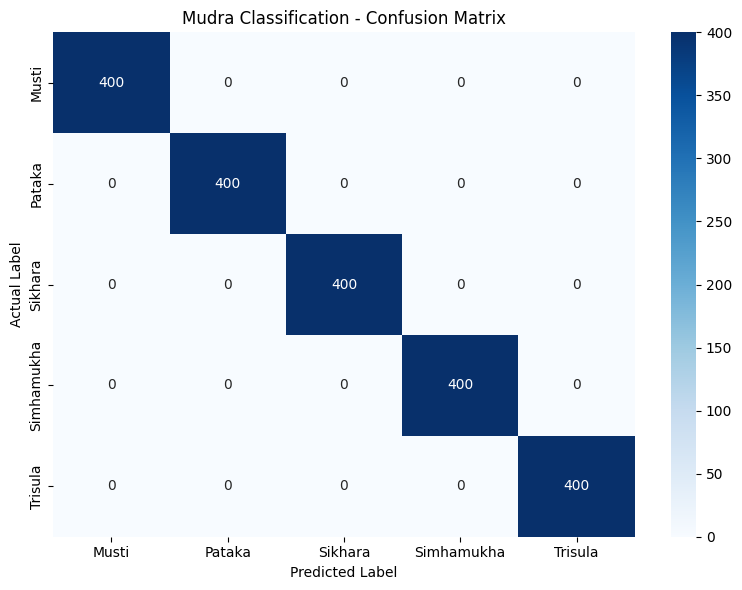

In [26]:
#confustion matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Mudra Classification - Confusion Matrix")
plt.tight_layout()
plt.show()


In [27]:
# Find incorrect predictions
wrong_indices = np.where(y_true != y_pred)[0]

print("Total misclassified images:", len(wrong_indices))

# Display up to 15 errors
n = min(15, len(wrong_indices))

if n == 0:
    print("No misclassified images in the test dataset.")
else:
    plt.figure(figsize=(18, 12))

    for i, idx in enumerate(wrong_indices[:n]):
        actual = encoder.classes_[y_true[idx]]
        predicted = encoder.classes_[y_pred[idx]]
        confidence = y_prob[idx][y_pred[idx]] * 100

        plt.subplot(3, 5, i + 1)
        plt.imshow(np.clip(X_test[idx], 0, 1))
        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Confidence: {confidence:.2f}%",
            fontsize=9
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

Total misclassified images: 0
No misclassified images in the test dataset.


1. Which mudra pair is most frequently confused?
No mudra pair was confused in the test dataset because all test images were classified correctly. Therefore, there is no most-frequently-confused pair to identify.
2. Are misclassified samples low-confidence or high-confidence?
There are no misclassified samples, so their confidence levels cannot be analyzed. This suggests that the model performed very well on the test set, but it does not necessarily mean it will perform perfectly on new images.
3. Suggest one data-centric and one model-centric improvement.
- Data-centric improvement: Add more diverse mudra images with different lighting, backgrounds, hand orientations, and finger positions to improve generalization.
- Model-centric improvement: Use transfer learning with a pretrained model such as MobileNetV2 to potentially improve feature extraction and recognition of similar mudras.


In [28]:
from google.colab import files
uploaded = files.upload()

Saving Image_1754982452.2877748.jpg to Image_1754982452.2877748.jpg


['Musti' 'Pataka' 'Sikhara' 'Simhamukha' 'Trisula']
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
[[2.6516007e-13 8.6003669e-17 2.6430760e-14 1.0000000e+00 5.2012609e-11]]
Predicted class: 3
Predicted label: Simhamukha


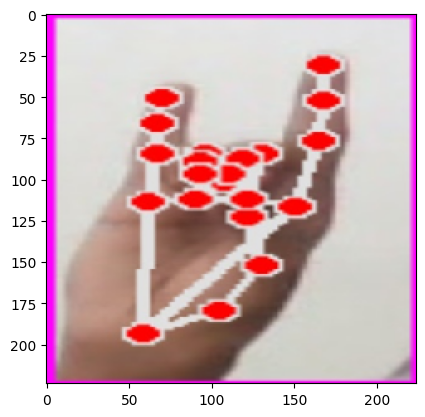

In [29]:
from tensorflow.keras.preprocessing import image
import numpy as np

# upload a new image
import matplotlib.pyplot as plt

print(encoder.classes_)
for img_name in uploaded.keys():
  img = image.load_img(img_name, target_size=(224, 224))
  plt.imshow(img)
  img_array = image.img_to_array(img) / 255.0
  img_array = np.expand_dims(img_array, axis=0)  # add batch dimension

  pred = model.predict(img_array)
  print(pred)
  predicted_class = np.argmax(pred, axis=1)[0]

  print("Predicted class:", predicted_class)
  print("Predicted label:", encoder.inverse_transform([predicted_class])[0])


1. Why is displaying prediction confidence important for end users?

It helps users understand how reliable the model’s prediction is and identify uncertain results.

2. What additional feature would make this application more useful for dance
learners?

Adding reference images or videos with step-by-step instructions would help dance learners practise and learn mudras correctly.


In [30]:
#save teh model for streamlit application
# Save the trained CNN model
best_model.save("mudra_cnn_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [31]:
import pickle

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(encoder, f)



In [32]:
# Implement Transfer Learning using MobileNetV2, EfficientNet, or ResNet50.
# Compare it with your custom CNN in terms of:
# ● Accuracy
# ● Model size
# ● Training time
# ● Inference speed
# Recommend the better deployment model with justification.


In [33]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    Dense, Dropout, GlobalAveragePooling2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

num_classes = len(train_ds.class_names) if hasattr(
    train_ds, "class_names"
) else len(set(y_train))

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)
output = Dense(num_classes, activation="softmax")(x)

model = Model(base_model.input, output)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

model.evaluate(test_ds)


Epoch 1/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.9218 - loss: 0.2427 - val_accuracy: 1.0000 - val_loss: 0.0227
Epoch 2/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9982 - loss: 0.0224 - val_accuracy: 1.0000 - val_loss: 0.0022
Epoch 3/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9994 - loss: 0.0089 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 4/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9994 - loss: 0.0045 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 5/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9988 - loss: 0.0046 - val_accuracy: 1.0000 - val_loss: 9.9757e-04
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 1.0000 - loss: 6.9796e-04


[0.0006979570025578141, 1.0]

In [34]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 1.0000 - loss: 6.9796e-04
Test Loss: 0.0007
Test Accuracy: 100.0 %


In [39]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y.numpy() for _, y in test_ds])

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=encoder.classes_,
    zero_division=0
))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
              precision    recall  f1-score   support

       Musti       1.00      1.00      1.00        30
      Pataka       1.00      1.00      1.00        30
     Sikhara       1.00      1.00      1.00        30
  Simhamukha       1.00      1.00      1.00        30
     Trisula       1.00      1.00      1.00        30

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



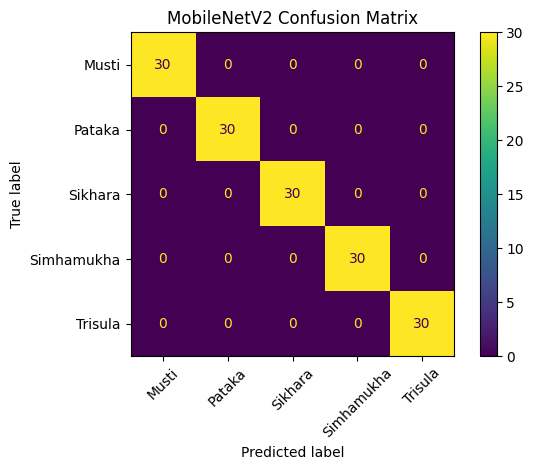

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
).plot(xticks_rotation=45)

plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

Since both models have the same test accuracy and MobileNetV2 is faster, I recommend MobileNetV2 for faster training.
Justification:
- Accuracy: Both models perform equally on the test dataset.